# `sperm_decay.ipynb`

This file estimates the rate that sperm decay in the zebrafish testis, using data from Cattelan & Gasparini (2021).

This data consists of sperm counts collected from a total of 70 fish after either 4, 7, or 12 days of accumulation. Fish sampled after 12 days have more sperm than fish sampled after 4 days, indicating that sperm can continue accumulating over the span of weeks. However, the fish at 12 days have less than triple the sperm at 4 days, showing that sperm is exiting the system. We will fit their data to an exponential decay model to estimate the rate $\delta$ (measured in units days$^{-1}$) that sperm decay.

**Reference**: Cattelan, S., & Gasparini, C. (2021). Male sperm storage impairs sperm quality in the zebrafish. Scientific reports, 11(1), 16689. [https://doi.org/10.1038/s41598-021-94976-x](https://doi.org/10.1038/s41598-021-94976-x)

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import curve_fit

In [2]:
small_label_settings = {
    'font.family': 'Arial',
    'font.size': 7,              # base font size
    'xtick.labelsize': 5,        # x-axis tick label size
    'ytick.labelsize': 5,        # y-axis tick label size
    'axes.labelsize': 7,         # axis label size
    'axes.titlesize': 7,         # title size
    'legend.fontsize': 7,        # legend font size
    'figure.titlesize': 7        # figure title size
}

In [3]:
df = pd.read_csv('./cattelan_data.csv')

In [4]:
# Convert days to months
df['months'] = df['days'] / 30

In [5]:
df.groupby('days').agg({'sperm_number': 'mean'})

,sperm_number
days,
4,158355.411765
7,195873.600000
12,254405.437500


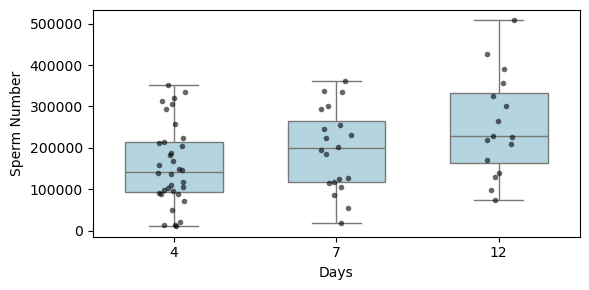

In [6]:
# Recreate figure 2(a) from the reference
plt.figure(figsize=(6, 3))

sns.boxplot(x='days', y='sperm_number', data=df, color='lightblue', width=0.6)
sns.stripplot(x='days', y='sperm_number', data=df, 
              color='black', size=4, jitter=True, alpha=0.6)

plt.xlabel('Days')
plt.ylabel('Sperm Number')

plt.tight_layout()
plt.show()

Assume that sperm is produced at constant rate $C$ and decays at rate $\delta$. Then between times $0$ and $T$, the expected number of sperm is $\int_0^T Ce^{\delta(T-t)}\, dt = C\frac{1-e^{-\delta T}}{\delta}$. We fit this model to the data.

In [7]:
def sperm_model(days, C, delta):
    return C * (1 - np.exp(-delta * days)) / delta

ind_var = df['months']
dep_var = df['sperm_number']

popt, pcov = curve_fit(sperm_model, ind_var, dep_var, p0 = [1, 1])

C, delta = popt
print(f'Fitted parameters:\nC     = {C:.0f}\ndelta = {delta:.4f} (month^-1)')

Fitted parameters:
C     = 1698090
delta = 6.2819 (month^-1)


In [8]:
perr = np.sqrt(np.diag(pcov))
print(f"Standard error of C:     {perr[0]:.2f}")
print(f"Standard error of delta: {perr[1]:.4f}")

Standard error of C:     385120.55
Standard error of delta: 2.3512


In [9]:
print(f'Confidence interval of delta: [{delta - perr[1]:.2f}-{delta + perr[1]:.2f}]')

Confidence interval of delta: [3.93-8.63]


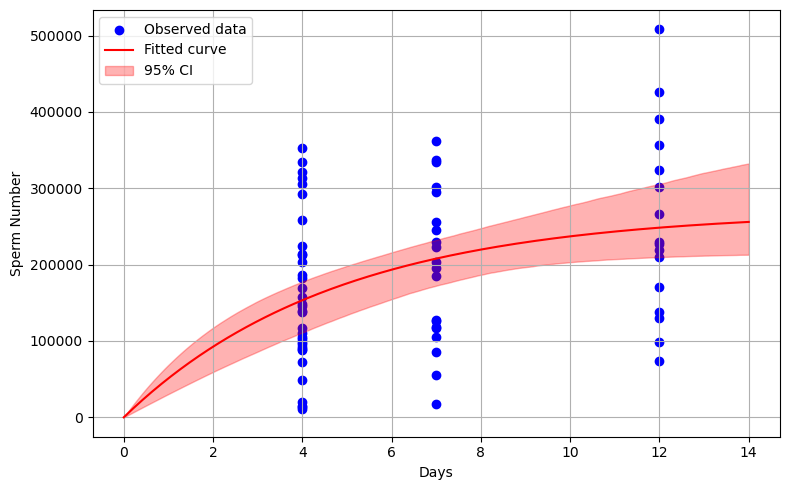

In [10]:
# Plot fit
x = np.linspace(0, 14, 200)
y = sperm_model(x / 30, C, delta)

# Sample parameter values
n_samples = 10000
samples = np.random.multivariate_normal(popt, pcov, size=n_samples)

# Generate curves from each sample, as well as confidence intervals
y_samples = np.array([sperm_model(x / 30, *params) for params in samples])
lower_bound = np.percentile(y_samples, 2.5, axis=0)
upper_bound = np.percentile(y_samples, 97.5, axis=0)

# Plot
plt.figure(figsize=(8, 5))
plt.scatter(df['days'], df['sperm_number'], label='Observed data', color='blue')
plt.plot(x, y, label='Fitted curve', color='red')
plt.fill_between(x, lower_bound, upper_bound, color='red', alpha=0.3, label='95% CI')
plt.xlabel('Days')
plt.ylabel('Sperm Number')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

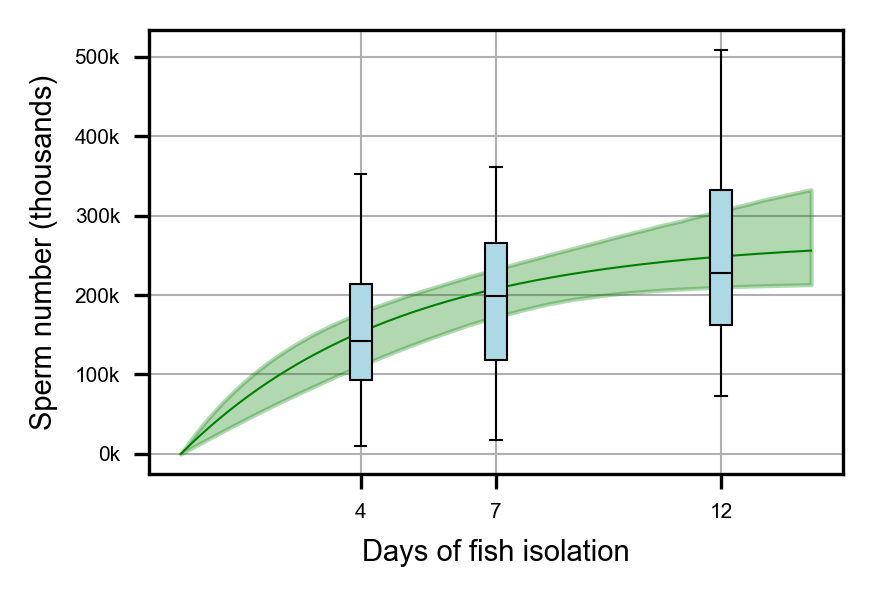

In [11]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, ax = plt.subplots(figsize=(3, 2), dpi=300)

# Create boxplots for each time point
days = sorted(df['days'].unique())
data_by_day = [df.loc[df['days'] == d, 'sperm_number'] for d in days]

plt.boxplot(
    data_by_day,
    positions=days,
    widths=0.5,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue', edgecolor='black', linewidth=0.5),
    medianprops=dict(color='black', linewidth=0.5),
    whiskerprops=dict(color='black', linewidth=0.5),
    capprops=dict(color='black', linewidth=0.5),
    label='Experimental sperm number'
)

# Overlay fitted curve and confidence interval
# Put curve underneath boxplots by using zorder
plt.plot(x, y, label='Fitted curve', color='green', linewidth=0.5, zorder=1)
plt.fill_between(x, lower_bound, upper_bound, color='green', alpha=0.3, label='95% CI', zorder=1)

plt.xlabel('Days of fish isolation')
plt.ylabel('Sperm number (thousands)')
plt.tight_layout()

ax.set_axisbelow(True)
plt.grid(True, linewidth=0.5)

import matplotlib.ticker as ticker
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k'))

plt.savefig('./images/sperm_decay_fit.svg', bbox_inches = 'tight', pad_inches = 0)